# Braun et al. (2026), Fig. 1 — different matrices, one connectivity profile (WP0.1)

Reproduction of Braun, Nordal, Rambø, Clopath & Gonzalo Cogno (2026), Fig. 1 (bioRxiv 10.64898/2026.09.02.748960),
panel by panel, from the Methods alone.

> Many FORCE-trained connectivity matrices generate the same sequence; they differ (pairwise matrix correlation ≈ 0.07)
> but share one connectivity profile (profile correlation ≈ 0.97–0.98). The mean matrix also generates the sequence.

**Panels:** A target activity of one unit · B target sequences and snippets · C matrix → circular shift → profile ·
D realisations 1 and 50 · E pairwise correlations · F mean matrix, its profile, its dynamics · G (added) self-weights.

**Acceptance (spec WP0.1 / Section 7 table):** matrix correlation < 0.15 and profile correlation > 0.95 across
realisations; test target–response correlation ≈ 0.8; mean |ΔW| still decreasing at iteration 300 (Supp. 1E, own
notebook). Also: is the Supp. 1G off-diagonal cluster the diagonal (self-weights)?

**Model and training:** `seqnet.models.rate_rnn`, `seqnet.training.rls` (Braun eq. 1–9) with the spec's default
[VERIFY] switches: error toward x* (`methods`), c with the updated P (as printed), state reset each iteration, target
evaluated at the exact update times. Settings and switches are printed below from the run's `meta.json`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from seqnet.figures import Figure, style
from seqnet.experiments import wp0
from seqnet import conventions as cv
from seqnet.sequences import braun_sequence, logit_target
from seqnet.models.rate_rnn import simulate, RNNParams
from seqnet.training.rls import pearson

style()
fig = Figure("wp0", "braun_fig1")
cfg = fig.config()
tg = cfg["target"]
run = wp0.get(tg["amp"], tg["width"], tg["offset"], cfg["settings"], store_full=cfg["store_full"])
S = run.summary
spec = braun_sequence(amp=tg["amp"], width=tg["width"], offset=tg["offset"])
N, T = spec.N, spec.T
{k: run.meta[k] for k in ("settings", "n_realizations", "git", "wall_time_total_s", "verify_switches")}

{'settings': 'final',
 'n_realizations': 50,
 'git': {'commit': 'fdc0848a13334567e47d0b3d5f85d8fe8a075d46',
  'dirty_seqnet': False},
 'wall_time_total_s': 3687.138790369034,
 'verify_switches': {'error_target': 'methods',
  'c_uses_updated_P': True,
  'state_reset': True,
  'target_time': 'analytic',
  'weight_decay': 0.0,
  'mask': None}}

## Panel A — target activity of one unit (Braun eq. 4–5)

In [2]:
t = np.linspace(0, 2 * T, 1000)
f = spec.stationary().profile(t - 2.0)
fig.save("A_unit_target", params=tg, t=t, f=f)

WindowsPath('C:/Users/max/Documents/phd-work/results/wp0/data/braun_fig1/A_unit_target.npz')

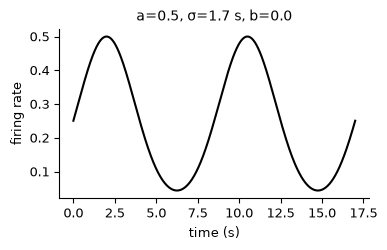

In [3]:
d = fig.load("A_unit_target")
F, ax = plt.subplots(figsize=(4, 2.2))
ax.plot(d["t"], d["f"], "k"); ax.set_xlabel("time (s)"); ax.set_ylabel("firing rate")
ax.set_title(f"a={tg['amp']}, σ={tg['width']} s, b={tg['offset']}")
fig.savefig("A_unit_target", F); plt.show()

## Panel B — target sequences (18 periods, 153 s) with two example 17-s snippets

Rates at the 0.129-s bins (Braun Methods lines 808–823); snippets start at the first two realisations' t0.

In [4]:
tb = np.arange(0, 18 * T, 0.129)
R = spec.rates(tb)
fig.save("B_target_sequences", t=tb[::2], R=R[:, ::2].astype(np.float32), t0=S["t0"][:2])

WindowsPath('C:/Users/max/Documents/phd-work/results/wp0/data/braun_fig1/B_target_sequences.npz')

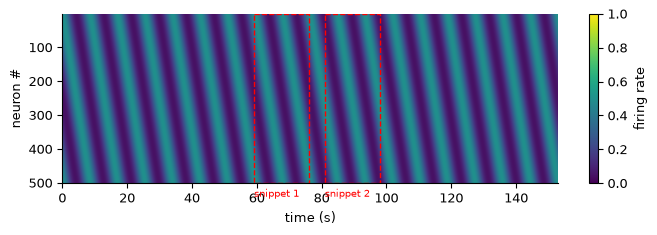

In [5]:
d = fig.load("B_target_sequences")
F, ax = plt.subplots(figsize=(8, 2.2))
im = ax.imshow(d["R"], aspect="auto", extent=[d["t"][0], d["t"][-1], N, 1], vmin=0, vmax=1)
for i, t0 in enumerate(d["t0"]):
    ax.add_patch(plt.Rectangle((t0, 1), 17, N - 1, fill=False, ec="r", ls="--")); ax.text(t0, N + 40, f"snippet {i+1}", color="r", fontsize=7)
ax.set_xlabel("time (s)"); ax.set_ylabel("neuron #"); F.colorbar(im, ax=ax, label="firing rate")
fig.savefig("B_target_sequences", F); plt.show()

## Panel C — from a matrix to its connectivity profile

Each row of W is circularly shifted so the self-connection sits at distance 0; the profile is the mean over rows
(Braun eq. 11; cp_d = (1/N) Σ_n W[n, (n+d) mod N], d = presynaptic − postsynaptic).

In [6]:
W1 = run.W(0)
n = np.arange(N)
shifted = np.stack([np.roll(W1[i], -(i - N // 2)) for i in range(N)])  # self-connection in the middle column
dd, cp1 = cv.centred_profile(cv.profile_from_matrix(W1))
fig.save("C_shift_profile", W=W1.astype(np.float32), shifted=shifted.astype(np.float32), d=dd, cp=cp1)

WindowsPath('C:/Users/max/Documents/phd-work/results/wp0/data/braun_fig1/C_shift_profile.npz')

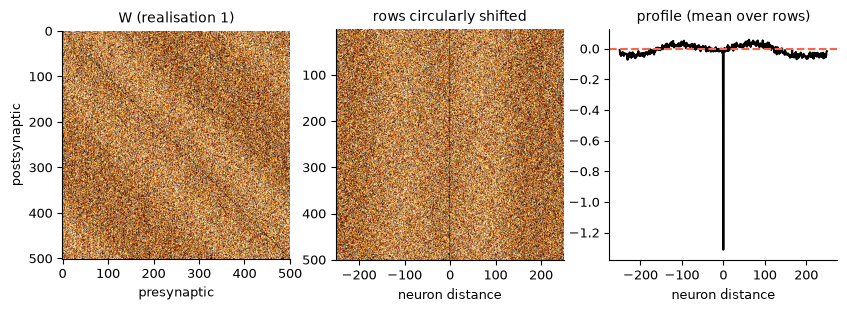

In [7]:
d = fig.load("C_shift_profile"); c = cfg["display_clip"]
F, axs = plt.subplots(1, 3, figsize=(10, 3))
axs[0].imshow(d["W"], cmap="afmhot", vmin=-c, vmax=c); axs[0].set_title("W (realisation 1)"); axs[0].set_xlabel("presynaptic"); axs[0].set_ylabel("postsynaptic")
axs[1].imshow(d["shifted"], cmap="afmhot", vmin=-c, vmax=c, extent=[-N // 2, N // 2, N, 1], aspect="auto"); axs[1].set_title("rows circularly shifted"); axs[1].set_xlabel("neuron distance")
axs[2].plot(d["d"], d["cp"], "k"); axs[2].axhline(0, color="tomato", ls="--"); axs[2].set_title("profile (mean over rows)"); axs[2].set_xlabel("neuron distance")
fig.savefig("C_shift_profile", F); plt.show()

## Panel D — realisations 1 and 50: matrices and profiles

In [8]:
R_last = run.meta["n_realizations"] - 1
WA, WB = run.W(0), run.W(R_last)
_, cpA = cv.centred_profile(cv.profile_from_matrix(WA)); _, cpB = cv.centred_profile(cv.profile_from_matrix(WB))
fig.save("D_two_realisations", WA=WA.astype(np.float32), WB=WB.astype(np.float32), d=dd, cpA=cpA, cpB=cpB,
         corr_W=pearson(WA, WB), corr_cp=pearson(cpA, cpB), last=R_last)

WindowsPath('C:/Users/max/Documents/phd-work/results/wp0/data/braun_fig1/D_two_realisations.npz')

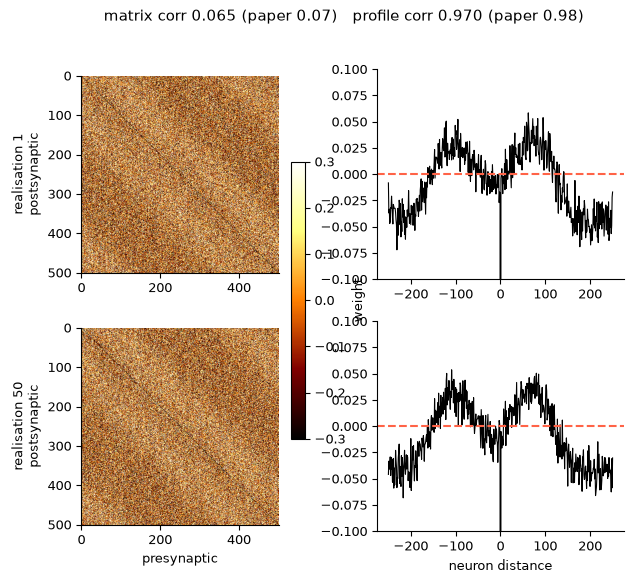

In [9]:
d = fig.load("D_two_realisations"); c = cfg["display_clip"]
F, axs = plt.subplots(2, 2, figsize=(7, 6))
for row, (Wk, cpk, lab) in enumerate([(d["WA"], d["cpA"], "realisation 1"), (d["WB"], d["cpB"], f"realisation {int(d['last'])+1}")]):
    im = axs[row, 0].imshow(Wk, cmap="afmhot", vmin=-c, vmax=c); axs[row, 0].set_ylabel(f"{lab}\npostsynaptic")
    axs[row, 1].plot(d["d"], cpk, "k", lw=0.8); axs[row, 1].axhline(0, color="tomato", ls="--"); axs[row, 1].set_ylim(-0.1, 0.1)
axs[1, 0].set_xlabel("presynaptic"); axs[1, 1].set_xlabel("neuron distance"); F.colorbar(im, ax=axs[:, 0], shrink=0.6, label="weight")
F.suptitle(f"matrix corr {float(d['corr_W']):.3f} (paper 0.07)   profile corr {float(d['corr_cp']):.3f} (paper 0.98)")
fig.savefig("D_two_realisations", F); plt.show()

## Panel E — distribution of pairwise correlations across all realisations

In [10]:
fig.save("E_pairwise", matrix_corr=S["matrix_corr"], profile_corr=S["profile_corr"])

WindowsPath('C:/Users/max/Documents/phd-work/results/wp0/data/braun_fig1/E_pairwise.npz')

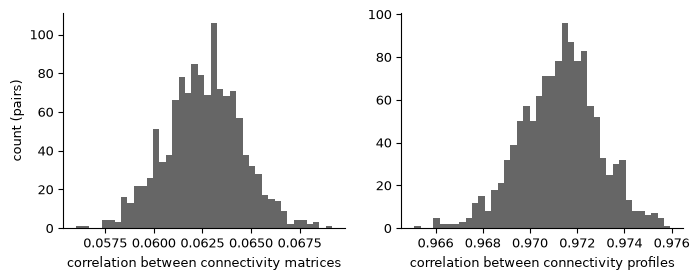

matrix corr  median 0.063  [0.056, 0.069]
profile corr median 0.971  [0.965, 0.976]


In [11]:
d = fig.load("E_pairwise")
F, axs = plt.subplots(1, 2, figsize=(8, 2.8))
axs[0].hist(d["matrix_corr"], bins=40, color="0.4"); axs[0].set_xlabel("correlation between connectivity matrices"); axs[0].set_ylabel("count (pairs)")
axs[1].hist(d["profile_corr"], bins=40, color="0.4"); axs[1].set_xlabel("correlation between connectivity profiles")
fig.savefig("E_pairwise", F); plt.show()
print("matrix corr  median %.3f  [%.3f, %.3f]" % (np.median(d["matrix_corr"]), d["matrix_corr"].min(), d["matrix_corr"].max()))
print("profile corr median %.3f  [%.3f, %.3f]" % (np.median(d["profile_corr"]), d["profile_corr"].min(), d["profile_corr"].max()))

## Panel F — mean matrix, its profile, and the dynamics it generates

The mean matrix is run (with noise, as in training) for 17 s from h_target(0).

In [12]:
Wm = S["mean_W"]
_, cpm = cv.centred_profile(cv.profile_from_matrix(Wm))
prm = RNNParams()
n_steps = int(round(cfg["dynamics_seconds"] / prm.dt))
sim = simulate(Wm, logit_target(spec, 0.0)[:, 0], n_steps, prm, np.random.default_rng(cfg["seed_dynamics"]), record_every=16)
t_rec = sim["t"] * prm.dt
corr_dyn = pearson(sim["r"].T, spec.rates(t_rec))
fig.save("F_mean_matrix", Wm=Wm.astype(np.float32), d=dd, cp=cpm, r=sim["r"].T.astype(np.float32), t=t_rec, corr=corr_dyn)

WindowsPath('C:/Users/max/Documents/phd-work/results/wp0/data/braun_fig1/F_mean_matrix.npz')

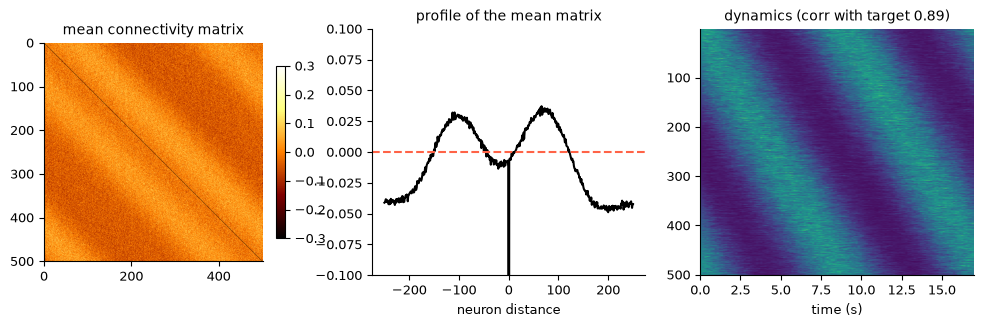

In [13]:
d = fig.load("F_mean_matrix"); c = cfg["display_clip"]
F, axs = plt.subplots(1, 3, figsize=(12, 3.2))
im = axs[0].imshow(d["Wm"], cmap="afmhot", vmin=-c, vmax=c); axs[0].set_title("mean connectivity matrix"); F.colorbar(im, ax=axs[0], shrink=0.7)
axs[1].plot(d["d"], d["cp"], "k"); axs[1].axhline(0, color="tomato", ls="--"); axs[1].set_ylim(-0.1, 0.1); axs[1].set_title("profile of the mean matrix"); axs[1].set_xlabel("neuron distance")
im = axs[2].imshow(d["r"], aspect="auto", extent=[0, d["t"][-1], N, 1], vmin=0, vmax=1); axs[2].set_title(f"dynamics (corr with target {float(d['corr']):.2f})"); axs[2].set_xlabel("time (s)")
fig.savefig("F_mean_matrix", F); plt.show()

## Panel G (added) — self-connections

Spec WP0.1 asks whether the strongly negative spike at d = 0 (Fig. 1D, F) and the separate cluster in Supp. 1G are
the diagonal. Distribution of self-weights against off-diagonal weights, realisation 1, and the mean self-weight across
realisations.

In [14]:
diag1 = np.diag(run.W(0)); off1 = run.W(0)[~np.eye(N, dtype=bool)]
fig.save("G_self_weights", diag=diag1, off_sample=np.random.default_rng(0).choice(off1, 5000, replace=False), diag_mean=S["diag_mean"])

WindowsPath('C:/Users/max/Documents/phd-work/results/wp0/data/braun_fig1/G_self_weights.npz')

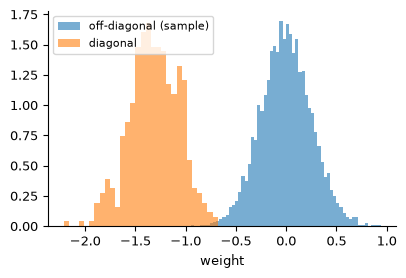

mean self-weight per realisation: -1.308 ± 0.010


In [15]:
d = fig.load("G_self_weights")
F, ax = plt.subplots(figsize=(4.5, 2.8))
ax.hist(d["off_sample"], bins=60, density=True, alpha=0.6, label="off-diagonal (sample)")
ax.hist(d["diag"], bins=30, density=True, alpha=0.6, label="diagonal")
ax.set_xlabel("weight"); ax.legend()
fig.savefig("G_self_weights", F); plt.show()
print("mean self-weight per realisation: %.3f ± %.3f" % (d["diag_mean"].mean(), d["diag_mean"].std()))

## Acceptance

In [16]:
mc, pc = S["matrix_corr"], S["profile_corr"]
test_corr = S["corr"][:, -run.config.n_test:].mean()
dW = S["dW"].mean(0); n_tr = run.config.n_train
fig.checks([
    {"item": "matrices differ across realisations", "criterion": "median pairwise matrix correlation < 0.15 (paper ~0.07)",
     "value": float(np.median(mc)), "passed": bool(np.median(mc) < 0.15)},
    {"item": "profiles agree across realisations", "criterion": "median pairwise profile correlation > 0.95 (paper 0.97-0.98)",
     "value": float(np.median(pc)), "passed": bool(np.median(pc) > 0.95)},
    {"item": "test target-response correlation", "criterion": "about 0.8 (reported; |x - 0.8| < 0.1)",
     "value": float(test_corr), "passed": bool(abs(test_corr - 0.8) < 0.1)},
    {"item": "mean |dW| still decreasing at the end of training", "criterion": "mean over last 10 train iterations < mean over the 10 before",
     "value": [float(dW[n_tr - 20:n_tr - 10].mean()), float(dW[n_tr - 10:n_tr].mean())], "passed": bool(dW[n_tr - 10:n_tr].mean() < dW[n_tr - 20:n_tr - 10].mean())},
    {"item": "mean matrix generates the sequence", "criterion": "corr(dynamics, target) > 0.5 (reported)",
     "value": float(fig.load("F_mean_matrix")["corr"]), "passed": bool(fig.load("F_mean_matrix")["corr"] > 0.5)},
    {"item": "self-weights (diagonal) strongly negative", "criterion": "reported", "value": float(S["diag_mean"].mean()), "passed": None},
])

[PASS] matrices differ across realisations: 0.06259056760974675
[PASS] profiles agree across realisations: 0.9713677410118955
[PASS] test target-response correlation: 0.8756385513084228
[PASS] mean |dW| still decreasing at the end of training: [0.011307981041563152, 0.010974381810928578]
[PASS] mean matrix generates the sequence: 0.8918748115933389
[info] self-weights (diagonal) strongly negative: -1.3080520753708822


WindowsPath('C:/Users/max/Documents/phd-work/results/wp0/data/braun_fig1/acceptance.json')